# Module 4 — Integration architecture, runnable

**The problem.** A model is not a system. Between your application and the model sits a layer that copes with the one thing a database never does: **the output is probabilistic**. This notebook builds and *measures* that layer — a gateway/adapter, three-tier validation, failure routing, a circuit breaker, caching, and the latency distribution AI uniquely needs.

The companion `integration-architecture` **skill** produces the integration doc + secure code for a real project. We use the real model (`qwen2.5:7b`) where its *behaviour* is the point, and clearly-labelled deterministic **sims** where the *control flow* is the point (fault injection — the standard way to test resilience paths, so the lesson doesn't ride on a flaky run). Each block is demonstrated in isolation; the diagram at the end shows how they compose.


## 0. Setup


In [1]:
import sys, pathlib, importlib, time, math, json as _json, re, hashlib, statistics
here = pathlib.Path.cwd()
for p in (here, here/"notebooks", here.parent):
    if (p/"arch_kit.py").exists(): sys.path.insert(0, str(p)); break
import arch_kit; importlib.reload(arch_kit)
from arch_kit import chat

def parse_json(txt):
    m = re.search(r"\{.*\}", txt, re.S)
    if not m: return None
    try: return _json.loads(m.group(0))
    except Exception: return None

def chat_raw(prompt, system="", num_predict=60, model=None):
    """chat + the raw Ollama timing fields (token counts, prefill vs decode durations in ns)."""
    model = model or arch_kit.CHAT_MODEL
    msgs = ([{"role":"system","content":system}] if system else []) + [{"role":"user","content":prompt}]
    r = arch_kit._post("/api/chat", {"model":model,"messages":msgs,"stream":False,
                                     "options":{"temperature":0.0,"num_predict":num_predict}})
    return r.get("message",{}).get("content","").strip(), r
print("ready —", arch_kit.CHAT_MODEL, "via", arch_kit.OLLAMA)


ready — qwen2.5:7b via http://127.0.0.1:11434


## 1. Gateway + adapter — swap the route by config, not code

Callers never hold a provider SDK. They call a thin **adapter**; behind it a **gateway** routes by task and tags the call for cost attribution. Below we *perform* the swap — change the route table and re-run the **same** caller on the **same** input, so the only variable is the config.


In [2]:
ROUTES = {"classify": {"model": "qwen2.5:7b", "num_predict": 20,  "tier": "tier-A"},
          "draft":    {"model": "qwen2.5:7b", "num_predict": 200, "tier": "frontier"}}
CALLS = {}   # counts CALLS per tier (not tokens/cost) for attribution

def gateway(task, prompt, system=""):
    cfg = ROUTES[task]
    CALLS[cfg["tier"]] = CALLS.get(cfg["tier"], 0) + 1
    return chat(prompt, system=system, model=cfg["model"], num_predict=cfg["num_predict"])

def adapter_classify(text):   # the caller's stable interface — no provider details leak through
    return gateway("classify", text, system="Reply with ONE word: positive, negative, or neutral.").strip()

txt = "The billing page keeps crashing and nobody replied for a week."
print("call 1:", adapter_classify(txt), "| active route:", ROUTES["classify"])
# --- swap BY CONFIG: same caller, same input; only the route table changes ---
ROUTES["classify"] = {"model": "qwen2.5:7b", "num_predict": 20, "tier": "tier-B"}  # the 'model' field is where you'd point at another provider / self-host
print("call 2:", adapter_classify(txt), "| active route:", ROUTES["classify"])
print("CALLS by tier:", CALLS, "-> same input, same caller code; the config moved the traffic A -> B")


call 1: negative | active route: {'model': 'qwen2.5:7b', 'num_predict': 20, 'tier': 'tier-A'}
call 2: negative | active route: {'model': 'qwen2.5:7b', 'num_predict': 20, 'tier': 'tier-B'}
CALLS by tier: {'tier-A': 1, 'tier-B': 1} -> same input, same caller code; the config moved the traffic A -> B


**Read it.** The caller said `adapter_classify(txt)` on the **same input** both times and never named a model, provider, or tier. We swapped `ROUTES['classify']` between the calls and `CALLS` shows the traffic move `tier-A` → `tier-B` — the route moved by **config**, the caller untouched. Here only the attribution changed (same local model, which is all we have); the **`model` field is where you'd point at a different provider or self-host** — and *that* swap moves the call but does **not** preserve behaviour, so you re-run your eval set after every model change (Section 2 validates every output for exactly this reason).


## 2. Three-tier output validation — schema → semantic → business rule

Validate cheapest-first and **stop at the first failure**. Tier 1: right shape (valid JSON, required keys, right types)? Tier 2: plausible values (positive amount, known currency)? Tier 3: obeys the *business* rules (within the approval cap)? We put the **validator under test** with crafted outputs — deterministic, so the tier boundaries are unambiguous.


In [3]:
ALLOWED_CURRENCY = {"CHF","EUR","USD"}
ALLOWED_CATEGORY = {"travel","meals","equipment","other"}
APPROVAL_CAP = 10_000

def validate(obj):
    # Tier 1 — schema (note: bool is a subclass of int, so exclude it explicitly)
    if not isinstance(obj, dict):                              return (1, False, "not a JSON object")
    for k in ("amount","currency","category"):
        if k not in obj:                                      return (1, False, f"missing key: {k}")
    if isinstance(obj["amount"], bool) or not isinstance(obj["amount"], (int, float)):
                                                              return (1, False, "amount is not a number")
    if not isinstance(obj["currency"], str) or not isinstance(obj["category"], str):
                                                              return (1, False, "currency/category not a string")
    # Tier 2 — semantic sanity
    if obj["amount"] <= 0:                                    return (2, False, "amount must be positive")
    if obj["currency"] not in ALLOWED_CURRENCY:               return (2, False, f"currency {obj['currency']!r} not allowed")
    if obj["category"] not in ALLOWED_CATEGORY:               return (2, False, f"category {obj['category']!r} not allowed")
    # Tier 3 — business rule
    if obj["amount"] > APPROVAL_CAP:                          return (3, False, f"amount {obj['amount']} over approval cap {APPROVAL_CAP}")
    return (0, True, "ok")

cases = [
    {"amount": 42.5, "currency": "CHF", "category": "meals"},        # ok
    "here is your expense: 42 CHF for lunch",                        # not JSON -> tier 1
    {"amount": -5, "currency": "CHF", "category": "meals"},          # tier 2 (negative)
    {"amount": 300, "currency": "XYZ", "category": "meals"},         # tier 2 (currency)
    {"amount": 50_000, "currency": "EUR", "category": "equipment"},  # tier 3 (over cap, schema+semantic valid!)
    {"amount": 7, "category": "meals"},                             # tier 1 (missing key) even though amount is fine
]
for c in cases:
    tier, ok, why = validate(c)
    print(f"tier={tier} ok={ok!s:5} {why:40} <- {str(c)[:46]}")


tier=0 ok=True  ok                                       <- {'amount': 42.5, 'currency': 'CHF', 'category'
tier=1 ok=False not a JSON object                        <- here is your expense: 42 CHF for lunch
tier=2 ok=False amount must be positive                  <- {'amount': -5, 'currency': 'CHF', 'category': 
tier=2 ok=False currency 'XYZ' not allowed               <- {'amount': 300, 'currency': 'XYZ', 'category':
tier=3 ok=False amount 50000 over approval cap 10000     <- {'amount': 50000, 'currency': 'EUR', 'category
tier=1 ok=False missing key: currency                    <- {'amount': 7, 'category': 'meals'}


**Read it.** Each bad output is caught at the **cheapest tier that can see the problem**, and we stop there — note the last case: a missing key is caught at tier 1 even though the amount is fine, because we don't run semantic/business checks on a mis-shaped object. The headline case is `50000 EUR equipment`: *perfectly valid JSON* with sane values, so schema and semantic tiers pass it, and only the **business rule** (the approval cap) catches it. A validator that stopped at 'is it valid JSON?' would wave a 50,000 expense straight through.


In [4]:
# ...and the real model, end to end: extract -> validate -> report the tier it landed in. Includes an
# input that SHOULD trip the business rule, so a real over-cap extraction is visible, not just promised.
SYS = ('Extract the expense as JSON only: {"amount": <number>, "currency": "CHF|EUR|USD", '
       '"category": "travel|meals|equipment|other"}. Output JSON and nothing else.')
for text in ["Lunch with the client, 38.50 francs.",
             "Bought a laptop for the new hire, 2400 EUR.",
             "Server rack for the new office, 25000 EUR."]:
    out = chat(text, system=SYS, num_predict=80)
    obj = parse_json(out)
    tier, ok, why = validate(obj) if obj is not None else (1, False, "unparseable")
    print(f"input: {text}\n   model: {out.strip()[:70]!r}\n   validation: tier={tier} ok={ok} ({why})\n")


input: Lunch with the client, 38.50 francs.
   model: '{"amount": 38.5, "currency": "CHF", "category": "meals"}'
   validation: tier=0 ok=True (ok)



input: Bought a laptop for the new hire, 2400 EUR.
   model: '{"amount": 2400, "currency": "EUR", "category": "equipment"}'
   validation: tier=0 ok=True (ok)



input: Server rack for the new office, 25000 EUR.
   model: '{"amount": 25000, "currency": "EUR", "category": "equipment"}'
   validation: tier=3 ok=False (amount 25000 over approval cap 10000)



**Read it.** The first two are clean, in-range JSON — they pass all three tiers. The third is a real 25,000 EUR extraction: schema and semantic valid, **caught at tier 3** by the approval cap, exactly as the crafted case predicted. You only know the good ones are good because the validator checked every output — not because the model promised.


## 3. Failure routing — retry *with a correction*, fall back, or escalate

The tier that failed decides what happens next. A **schema** fault is usually form — feed the error back and the model often fixes it (**retry-with-correction**). A **business-rule** fault is different: you cannot tell from the output whether it's a policy violation or a *hallucinated* number (text said 500, model wrote 50,000), and a correction that mentions the cap just biases the model toward an in-cap number — **laundering** the violation into a pass. So business-rule faults **escalate** (a human sees the source text), never retry. Exhausted retries fall back to a deterministic answer.


In [5]:
def route(tier):
    return {0:"accept", 1:"retry-with-correction", 2:"retry-with-correction", 3:"escalate (never retried)"}[tier]
for t in (0,1,2,3): print(f"tier {t} -> {route(t)}")

# the retry loop threads the validation error back as a CORRECTION (shown on a SIMULATED provider so the
# control flow is deterministic). The sim only recovers once it RECEIVES a correction -> the fix is the correction.
def resilient_generate(provider, max_retries=2):
    attempts, last_error = 0, None
    while attempts <= max_retries:
        obj = parse_json(provider(attempts, last_error))
        tier, ok, why = validate(obj) if obj is not None else (1, False, "unparseable")
        if ok:                                 return {"status":"ok", "attempts":attempts+1, "obj":obj}
        if route(tier).startswith("escalate"): return {"status":"escalated", "attempts":attempts+1, "reason":why}
        last_error = why                       # <- fed to the next attempt as the correction
        attempts += 1
    return {"status":"fallback", "attempts":attempts, "reason":"retries exhausted"}

def make_flaky():
    seen = []
    def provider(attempt, correction):
        seen.append(correction)                             # record what each attempt received
        if not correction: return "sure! 42 CHF for meals"  # malformed until a correction arrives
        return '{"amount": 42, "currency": "CHF", "category": "meals"}'
    return provider, seen

flaky, flaky_seen = make_flaky()
print("\nschema fault (corrected):", resilient_generate(flaky))
print("  what each attempt received:", flaky_seen, " <- attempt 2 got the error fed back as a correction")
print("business-rule fault      :", resilient_generate(lambda a, c: '{"amount": 50000, "currency": "EUR", "category": "equipment"}'))
print("never-valid fault        :", resilient_generate(lambda a, c: "not json at all"))


tier 0 -> accept
tier 1 -> retry-with-correction
tier 2 -> retry-with-correction
tier 3 -> escalate (never retried)

schema fault (corrected): {'status': 'ok', 'attempts': 2, 'obj': {'amount': 42, 'currency': 'CHF', 'category': 'meals'}}
  what each attempt received: [None, 'unparseable']  <- attempt 2 got the error fed back as a correction
business-rule fault      : {'status': 'escalated', 'attempts': 1, 'reason': 'amount 50000 over approval cap 10000'}
never-valid fault        : {'status': 'fallback', 'attempts': 3, 'reason': 'retries exhausted'}


**Read it.** The schema fault recovers on **attempt 2** — and only because the correction was fed back (the sim returns valid JSON *only after it receives a correction*, so the recovery is the correction, not luck). The over-cap expense **escalates on attempt 1**: it is schema-valid, so a naive retry loop would re-send it or, worse, coax the model into trimming the number to pass — a laundered violation. The unparseable one exhausts retries and lands on a **deterministic fallback**. Caveat on tier 2: a value-fault correction must be *normalisation only* ("francs" → CHF); a correction that states the allowed set as a target invites the model to invent a passing value — the same laundering, so treat value-faults you can't normalise like tier 3.


## 4. Circuit breaker — trip to the fallback before every request fails

If the provider is down, you don't want every *incoming* request to each wait, time out, and fail. A **circuit breaker** trips after N consecutive failures and sends new traffic straight to the fallback until a cool-down — failing fast. (Simulated outage below. A real breaker counts only transport errors — timeouts/5xx/connection — not a caller's 4xx, and its state is per-process.)


In [6]:
class CircuitBreaker:
    def __init__(self, threshold=3): self.fails=0; self.threshold=threshold; self.open=False
    def call(self, fn):
        if self.open: return ("fallback", "breaker OPEN — not even attempting the provider")
        try:
            r = fn(); self.fails = 0; return ("ok", r)
        except Exception as e:                       # a real breaker filters to transport errors only
            self.fails += 1
            if self.fails >= self.threshold: self.open = True
            return ("error", f"{e} (consecutive fails: {self.fails})")

def down_provider(): raise ConnectionError("provider unreachable")   # simulated outage
cb = CircuitBreaker(threshold=3)
for i in range(6):
    status, detail = cb.call(down_provider)
    print(f"request {i}: {status:9} | {detail}")


request 0: error     | provider unreachable (consecutive fails: 1)
request 1: error     | provider unreachable (consecutive fails: 2)
request 2: error     | provider unreachable (consecutive fails: 3)
request 3: fallback  | breaker OPEN — not even attempting the provider
request 4: fallback  | breaker OPEN — not even attempting the provider
request 5: fallback  | breaker OPEN — not even attempting the provider


**Read it.** The first three requests actually try the (simulated-down) provider and fail; on the third the breaker **opens**, and every request after returns the fallback *immediately* without touching the dead provider. That is the difference between a 3-request blip and new traffic piling up on timeouts. A real breaker adds a cool-down (a half-open probe) to test recovery.


## 5. Caching — the cheapest request is the one you don't make

An exact-match cache serves a repeated request instantly. The key must cover the **full** call — model, system, prompt, decode settings, and a prompt **version** — or a hit will serve a stale answer after any of those change. In a real pipeline you cache **validated** output only (the diagram writes the cache on the `ok` path).


In [7]:
PROMPT_VERSION = "v1"
CACHE = {}
def cache_key(model, system, prompt, num_predict):
    raw = f"{PROMPT_VERSION}|{model}|{num_predict}|{system}||{prompt}"
    return hashlib.sha256(raw.encode()).hexdigest()

def cached_chat(prompt, system="", num_predict=60, model=None):
    model = model or arch_kit.CHAT_MODEL
    key = cache_key(model, system, prompt, num_predict)
    t0 = time.perf_counter()
    if key in CACHE:
        return CACHE[key], True, time.perf_counter() - t0
    out = chat(prompt, system=system, num_predict=num_predict, model=model)
    dt = time.perf_counter() - t0
    CACHE[key] = out
    return out, False, dt

p = "In one sentence, what is a circuit breaker in software?"
a1, hit1, dt1 = cached_chat(p); print(f"call 1 (same): hit={hit1}  {dt1*1000:.1f} ms")
a2, hit2, dt2 = cached_chat(p); print(f"call 2 (same): hit={hit2}  {dt2*1000:.3f} ms   identical={a1==a2}")
a3, hit3, dt3 = cached_chat(p, num_predict=10); print(f"call 3 (num_predict changed): hit={hit3}  (full key -> a MISS, correctly)")


call 1 (same): hit=False  4278.9 ms
call 2 (same): hit=True  0.001 ms   identical=True


call 3 (num_predict changed): hit=False  (full key -> a MISS, correctly)


**Read it.** The second identical request was a hit: same answer, sub-millisecond, no tokens. The third changed only `num_predict` and correctly **missed** — because the key includes it. A key of just `system+prompt` (a common bug) would have returned the 60-token answer for a 10-token request. Cache on real traffic where requests repeat or paraphrase (a *semantic* cache with an embedding threshold catches paraphrases), key on the full context + version, and — in the pipeline — cache only *validated* output so a malformed answer isn't served forever.


## 6. Latency is a distribution — and the tail is output-length variance

A fixed prompt with a fixed output cap is nearly constant in latency; the **tail** appears when the workload is *mixed* (short and long outputs), because generating tokens is the slow part. We measure a mixed workload — the kind the gateway actually routes — and then isolate the lever.


In [8]:
def pctl(xs, q):
    xs = sorted(xs); return xs[min(len(xs)-1, math.ceil(q*(len(xs)-1)))]

# MIXED workload: alternate a short (cap 20) and a long (cap 120) generation of the SAME prompt
P = "Describe the quarterly logistics operations in prose."
lat = []
for i in range(10):
    npred = 120 if i in (4, 9) else 20     # realistic mix: MOST requests short, a FEW long
    t0 = time.perf_counter(); chat(P, num_predict=npred); lat.append(time.perf_counter() - t0)
print(f"mixed workload n={len(lat)} (8 short + 2 long)  P50={pctl(lat,0.5):.2f}s  "
      f"P95={pctl(lat,0.95):.2f}s  max={max(lat):.2f}s  mean={statistics.mean(lat):.2f}s")
print("P50 is a short call; P95/max catch the long ones -> the gap IS the tail. (At n=10, P95==max; report max.)")

# WHY: prefill (reading the prompt) vs decode (generating) — read it from Ollama's own timers
_, meta = chat_raw(P, num_predict=120)
pe, ed = meta.get("prompt_eval_duration",0)/1e9, meta.get("eval_duration",0)/1e9
print(f"\none long call: prefill {meta.get('prompt_eval_count')} tok in {pe:.2f}s | "
      f"decode {meta.get('eval_count')} tok in {ed:.2f}s  -> decode is {ed/max(pe,1e-9):.0f}x the prefill here")

# the lever, one variable changed (same prompt, cap 10 vs 120)
for npred in (10, 120):
    t0 = time.perf_counter(); chat(P, num_predict=npred); print(f"cap={npred:3}  {time.perf_counter()-t0:5.2f}s")


mixed workload n=10 (8 short + 2 long)  P50=1.68s  P95=9.75s  max=9.75s  mean=3.27s
P50 is a short call; P95/max catch the long ones -> the gap IS the tail. (At n=10, P95==max; report max.)



one long call: prefill 37 tok in 0.13s | decode 120 tok in 9.96s  -> decode is 77x the prefill here


cap= 10   0.89s


cap=120   9.67s


**Read it.** On the **mixed** workload P50 is a short call while P95/max are the long ones — several times slower (see the printed numbers; exact seconds vary by run and hardware). *That gap is the tail*, and it is the two long (cap-120) generations out of ten. The token timers say why: **decode dominates prefill** for a short prompt, so latency tracks *output* length. Changing only the cap (10 vs 120 on the identical prompt) moves latency directly. (With a *long* RAG context, prefill can instead dominate — measure both for your workload.) Design the SLA and the load-balancer timeout against **P95/P99 on a representative mixed workload** (not the mean, and not a single fixed prompt), cap output tokens to pull the tail in, and stream first tokens so perceived latency stays low. At small n report the **max**, not a pretend 'P99'.


### The integration layer as a diagram

Each block above was shown in isolation; this is how they **compose** in one request path.


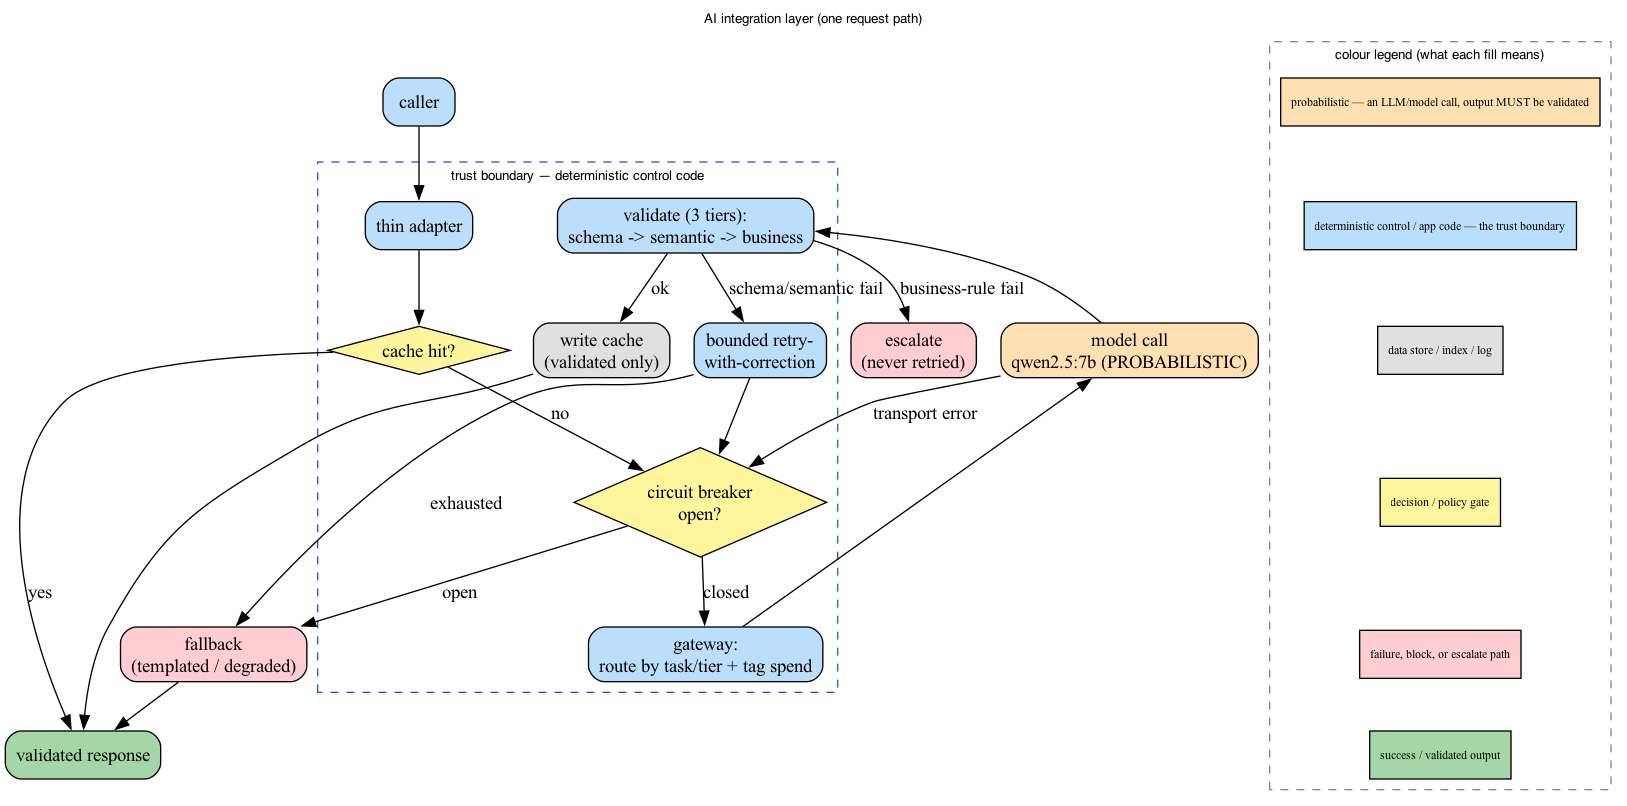

In [9]:
from graphviz import Digraph
from IPython.display import Image, display
from arch_kit import dnode, diagram_legend
g = Digraph(); g.attr(rankdir="TB", fontname="Helvetica", fontsize="10", labelloc="t",
                      label="AI integration layer (one request path)")
dnode(g,"app","caller","control")
with g.subgraph(name="cluster_tb") as c:
    c.attr(label="trust boundary — deterministic control code", style="dashed", color="#1565c0", fontsize="10")
    dnode(c,"adapter","thin adapter","control")
    dnode(c,"hit","cache hit?","gate")
    dnode(c,"br","circuit breaker\nopen?","gate")
    dnode(c,"gw","gateway:\nroute by task/tier + tag spend","control")
    dnode(c,"val","validate (3 tiers):\nschema -> semantic -> business","control")
    dnode(c,"retry","bounded retry-\nwith-correction","control")
    dnode(c,"cache","write cache\n(validated only)","data")
dnode(g,"model","model call\nqwen2.5:7b (PROBABILISTIC)","model")
dnode(g,"esc","escalate\n(never retried)","fail")
dnode(g,"fb","fallback\n(templated / degraded)","fail")
dnode(g,"out","validated response","ok")
g.edge("app","adapter"); g.edge("adapter","hit")
g.edge("hit","out",label="yes"); g.edge("hit","br",label="no")
g.edge("br","fb",label="open"); g.edge("br","gw",label="closed")
g.edge("gw","model"); g.edge("model","br",label="transport error"); g.edge("model","val")
g.edge("val","retry",label="schema/semantic fail"); g.edge("retry","br"); g.edge("retry","fb",label="exhausted")
g.edge("val","esc",label="business-rule fail"); g.edge("val","cache",label="ok")
g.edge("cache","out"); g.edge("fb","out")
diagram_legend(g, ["model","control","data","gate","fail","ok"])
try: display(Image(g.pipe(format="png")))
except Exception as e: print("diagram render skipped (needs the graphviz 'dot' binary):", e)


## 7. Meaningful tests

Each asserts a real behaviour of the layer, with its reason, and can fail. (The model is deliberately not under test here — these check the validator, the routing, the breaker, and the cache key.)


In [10]:
def run_checks():
    checks=[]
    def check(n,c,w): checks.append((n,"PASS" if c else "FAIL",w))

    check("schema tier rejects non-JSON / missing keys / wrong types",
          validate("x")[0]==1 and validate({"amount":1,"currency":"CHF"})[0]==1 and validate({"amount":True,"currency":"CHF","category":"meals"})[0]==1,
          "the cheapest check catches shape problems before anything else runs")
    check("stop-at-first: a mis-shaped object is tier 1 even if its amount is over cap",
          validate({"amount":50000,"currency":"EUR"})[0]==1,
          "we must not run business checks on an object that failed the schema check")
    check("semantic tier rejects a schema-valid but implausible value",
          validate({"amount":-5,"currency":"CHF","category":"meals"})[0]==2,
          "valid JSON can still be nonsense; tier 2 is where plausibility is enforced")
    check("business-rule tier rejects a schema+semantic-valid violation",
          validate({"amount":50000,"currency":"EUR","category":"equipment"})==(3,False,"amount 50000 over approval cap 10000"),
          "the 50k expense is valid JSON with sane values; only the domain rule catches it")
    check("a business-rule fault is ESCALATED, never retried",
          route(3).startswith("escalate") and
          resilient_generate(lambda a,c: '{"amount":50000,"currency":"EUR","category":"equipment"}')["status"]=="escalated",
          "retrying a policy violation burns tokens and risks laundering it into a pass")
    _prov, _seen = make_flaky()
    _res = resilient_generate(_prov)
    check("a schema fault recovers BECAUSE the correction was fed back",
          _res["attempts"]==2 and _seen[0] is None and _seen[1] is not None,
          "assert the 2nd attempt actually received the error -- not that it recovered by chance")
    check("exhausted retries land on a fallback, not an error",
          resilient_generate(lambda a,c: "never json")["status"]=="fallback",
          "a degraded deterministic answer beats a crash or a broken one")
    check("circuit breaker opens after the threshold and serves fallback",
          (lambda cb=CircuitBreaker(2): [cb.call(down_provider) for _ in range(2)] and cb.call(down_provider)[0]=="fallback")(),
          "fail fast once the provider is clearly down, instead of failing every request individually")
    m = arch_kit.CHAT_MODEL
    check("cache hits on an identical call and keys on the FULL context",
          cached_chat(p)[1] is True and cached_chat(p)[0]==a1
          and cache_key(m,"",p,10) != cache_key(m,"",p,60)
          and cache_key(m,"sys-v2",p,60) != cache_key(m,"",p,60),
          "a hit must be free and consistent; a changed decode setting or prompt must not collide")

    import pandas as pd
    print(pd.DataFrame(checks, columns=["check","result","why it matters"]).to_string(index=False))
    assert all(r=="PASS" for _,r,_ in checks), "an integration-layer guarantee broke"
    print("\nall", len(checks), "meaningful checks passed")
run_checks()


                                                                      check result                                                                             why it matters
                  schema tier rejects non-JSON / missing keys / wrong types   PASS                        the cheapest check catches shape problems before anything else runs
stop-at-first: a mis-shaped object is tier 1 even if its amount is over cap   PASS                  we must not run business checks on an object that failed the schema check
                 semantic tier rejects a schema-valid but implausible value   PASS                 valid JSON can still be nonsense; tier 2 is where plausibility is enforced
               business-rule tier rejects a schema+semantic-valid violation   PASS            the 50k expense is valid JSON with sane values; only the domain rule catches it
                          a business-rule fault is ESCALATED, never retried   PASS               retrying a policy violation burns

## Check your understanding

**Q1.** The `50000 EUR equipment` output passed the schema and semantic tiers. Why is a separate business-rule tier worth the extra code?
<details><summary>answer</summary>'Well-formed' and 'allowed' are different questions. Schema checks shape, semantic checks plausibility — both pass a 50,000 expense, because it *is* a valid number in a valid currency. Only a domain rule (the approval cap) knows it's wrong. Stop at 'valid JSON' and every structurally-correct policy violation sails through; the business tier is where the money is protected.</details>

**Q2.** Why escalate a business-rule failure rather than retry it, when a schema failure is retried?
<details><summary>answer</summary>A schema fault is usually *form* — a re-prompt with the error often fixes it. A business-rule fault is *content the rule forbids*, and you can't tell from the output whether it's a genuine over-cap request or a hallucinated number. A correction that mentions the cap biases the model toward a passing value, so a second answer can't be trusted — it launders the violation. Escalate so a human sees the source text. (Even some tier-2 value faults share this risk: only retry them when the fix is pure normalisation, never by stating the allowed values as a target.)</details>

**Q3.** A circuit breaker and a retry loop both handle failure. What does the breaker add?
<details><summary>answer</summary>Retries handle one request's transient fault. The breaker handles *systemic* failure: when the provider is down, retrying each of thousands of incoming requests multiplies load and waiting. The breaker trips after N consecutive failures and sends new traffic straight to the fallback — failing fast for everyone — then probes for recovery. Retries protect a call; the breaker protects the system from a dead dependency.</details>

**Q4.** The latency run showed P50 at a short call but P95/max several times higher. What drives that gap, and how do you measure latency honestly?
<details><summary>answer</summary>The gap is *output-length variance*: most calls were short (cap 20) and a couple long (cap 120), and generation time tracks output tokens — so the tail is the long generations (plus queueing in a real system). Measure on a **representative mixed workload** — the mix of short/long your gateway actually routes — with enough samples, and set the SLA/timeout against P95/P99 of *that*, not the mean and not a single fixed prompt (which has almost no spread). At small n report the max, not a 'P99' that's just the largest of a handful of draws. Then cap output tokens and stream first tokens to manage the tail.</details>
